In [3]:
print("Smart Customer Feedback Analyzer")
print("AI for Small Businesses")

Smart Customer Feedback Analyzer
AI for Small Businesses


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
url = "https://huggingface.co/datasets/Censius-AI/ECommerce-Women-Clothing-Reviews/resolve/main/Womens%20Clothing%20E-Commerce%20Reviews.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (23486, 11)


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [6]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  object
dtypes: int64(6), object(5)
memory usage: 2.0+ MB

Missing Values:
Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title             

In [8]:
# Remove reviews with missing text
df_clean = df.dropna(subset=["Review Text"]).copy()

# Remove extra spaces and empty reviews
df_clean["Review Text"] = df_clean["Review Text"].str.strip()
df_clean = df_clean[df_clean["Review Text"] != ""].copy()

# Remove unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"], errors="ignore")

# Create sentiment labels
def assign_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df_clean["Sentiment"] = df_clean["Rating"].apply(assign_sentiment)

print("Data cleaning completed!")
print("New dataset shape:", df_clean.shape)

print("\nSentiment Distribution:")
print(df_clean["Sentiment"].value_counts())

Data cleaning completed!
New dataset shape: (22641, 11)

Sentiment Distribution:
Sentiment
Positive    17448
Neutral      2823
Negative     2370
Name: count, dtype: int64


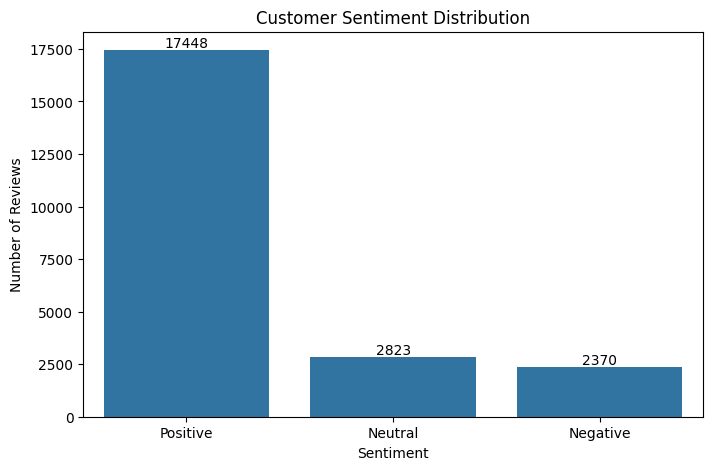


Sentiment Percentages:
Sentiment
Positive    77.06
Neutral     12.47
Negative    10.47
Name: proportion, dtype: float64


In [9]:
sentiment_order = ["Positive", "Neutral", "Negative"]

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x="Sentiment",
    order=sentiment_order
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

print("\nSentiment Percentages:")
print(
    (df_clean["Sentiment"].value_counts(normalize=True) * 100).round(2)
)

In [10]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


df_clean["Cleaned Review"] = df_clean["Review Text"].apply(clean_text)

print("Text preprocessing completed!")

display(
    df_clean[["Review Text", "Cleaned Review", "Sentiment"]].head()
)

Text preprocessing completed!


,Review Text,Cleaned Review,Sentiment
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...,Positive
1,Love this dress! it's sooo pretty. i happene...,love this dress it s sooo pretty i happened to...,Positive
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...,Neutral
3,"I love, love, love this jumpsuit. it's fun, fl...",i love love love this jumpsuit it s fun flirty...,Positive
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...,Positive


In [11]:
from sklearn.model_selection import train_test_split

X = df_clean["Cleaned Review"]
y = df_clean["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Data splitting completed!
Training samples: 18112
Testing samples: 4529


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF transformation completed!")
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

TF-IDF transformation completed!
Training data shape: (18112, 5000)
Testing data shape: (4529, 5000)


In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7714727312872599

Classification Report:
              precision    recall  f1-score   support

    Negative       0.47      0.61      0.53       474
     Neutral       0.32      0.46      0.38       565
    Positive       0.95      0.84      0.89      3490

    accuracy                           0.77      4529
   macro avg       0.58      0.64      0.60      4529
weighted avg       0.82      0.77      0.79      4529


Confusion Matrix:
[[ 291  152   31]
 [ 183  260  122]
 [ 146  401 2943]]


In [15]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print("Linear SVC Results:")
print(classification_report(y_test, svm_pred))

print("Accuracy:", accuracy_score(y_test, svm_pred))

Linear SVC Results:
              precision    recall  f1-score   support

    Negative       0.49      0.52      0.51       474
     Neutral       0.33      0.35      0.34       565
    Positive       0.91      0.90      0.90      3490

    accuracy                           0.79      4529
   macro avg       0.58      0.59      0.58      4529
weighted avg       0.79      0.79      0.79      4529

Accuracy: 0.7900198719364098


In [16]:
test_reviews = [
    "The dress is beautiful and the quality is amazing",
    "The delivery was late and customer service was terrible",
    "The product is okay, nothing special"
]

cleaned_reviews = [clean_text(review) for review in test_reviews]

reviews_tfidf = vectorizer.transform(cleaned_reviews)

predictions = model.predict(reviews_tfidf)

for review, sentiment in zip(test_reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Review: The dress is beautiful and the quality is amazing
Predicted Sentiment: Positive
--------------------------------------------------
Review: The delivery was late and customer service was terrible
Predicted Sentiment: Negative
--------------------------------------------------
Review: The product is okay, nothing special
Predicted Sentiment: Neutral
--------------------------------------------------


In [17]:
department_sentiment = df_clean.dropna(
    subset=["Department Name"]
).groupby(
    ["Department Name", "Sentiment"]
).size().unstack(fill_value=0)

department_percentage = department_sentiment.div(
    department_sentiment.sum(axis=1),
    axis=0
) * 100

print(department_percentage.round(2))

Sentiment        Negative  Neutral  Positive
Department Name                             
Bottoms              8.66    11.11     80.23
Dresses             11.08    13.51     75.41
Intimate             8.89    10.71     80.40
Jackets             10.78     8.98     80.24
Tops                10.91    12.94     76.15
Trend               17.80    16.10     66.10


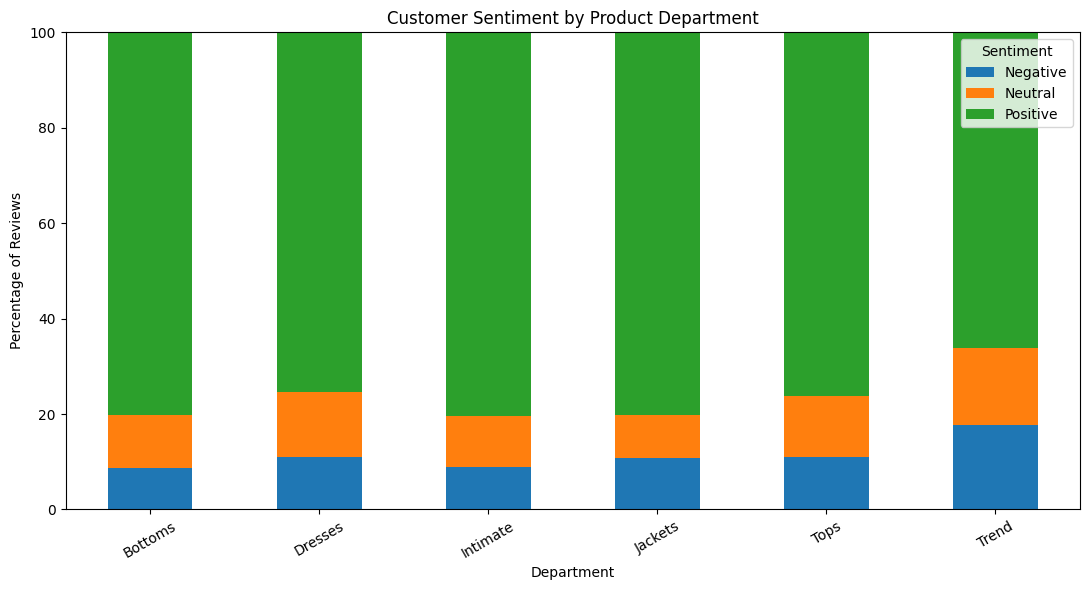

In [18]:
department_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    ylim=(0, 100)
)

plt.title("Customer Sentiment by Product Department")
plt.xlabel("Department")
plt.ylabel("Percentage of Reviews")
plt.legend(title="Sentiment")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [19]:
import joblib

joblib.dump(model, "sentiment_model.joblib")
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")

sentiment_summary = (
    df_clean["Sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Count")
)

department_summary = (
    df_clean.groupby(["Department Name", "Sentiment"])
    .size()
    .reset_index(name="Count")
)

sentiment_summary.to_csv("sentiment_summary.csv", index=False)
department_summary.to_csv("department_summary.csv", index=False)

print("Project files saved successfully!")

Project files saved successfully!


In [20]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
import re

st.set_page_config(
    page_title="Smart Customer Feedback Analyzer",
    page_icon="📊",
    layout="wide"
)

@st.cache_resource
def load_models():
    model = joblib.load("sentiment_model.joblib")
    vectorizer = joblib.load("tfidf_vectorizer.joblib")
    return model, vectorizer

@st.cache_data
def load_data():
    sentiment = pd.read_csv("sentiment_summary.csv")
    department = pd.read_csv("department_summary.csv")
    return sentiment, department

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

model, vectorizer = load_models()
sentiment_data, department_data = load_data()

st.title("Smart Customer Feedback Analyzer")
st.write("AI-powered customer feedback analysis for small businesses.")

st.divider()

st.header("Analyze Customer Review")

review = st.text_area(
    "Enter a customer review:",
    placeholder="Write the customer's feedback here..."
)

if st.button("Analyze Review"):
    if not review.strip():
        st.warning("Please enter a customer review.")
    else:
        cleaned_review = clean_text(review)

        if not cleaned_review:
            st.warning("Please enter a valid English review.")
        else:
            review_vector = vectorizer.transform([cleaned_review])
            prediction = model.predict(review_vector)[0]

            if prediction == "Positive":
                st.success("Sentiment: Positive 😊")
            elif prediction == "Negative":
                st.error("Sentiment: Negative ☹️")
            else:
                st.info("Sentiment: Neutral 😐")

st.divider()

st.header("Business Insights")

counts = sentiment_data.set_index("Sentiment")["Count"].to_dict()
total_reviews = sum(counts.values())

positive_count = counts.get("Positive", 0)
negative_count = counts.get("Negative", 0)
neutral_count = counts.get("Neutral", 0)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Reviews", f"{total_reviews:,}")
col2.metric("Positive Reviews", f"{positive_count:,}")
col3.metric("Negative Reviews", f"{negative_count:,}")
col4.metric("Neutral Reviews", f"{neutral_count:,}")

st.subheader("Customer Sentiment Distribution")

st.bar_chart(
    sentiment_data.set_index("Sentiment")
)

st.subheader("Customer Feedback by Department")

department_pivot = department_data.pivot_table(
    index="Department Name",
    columns="Sentiment",
    values="Count",
    fill_value=0
)

department_percentage = department_pivot.div(
    department_pivot.sum(axis=1),
    axis=0
) * 100

st.bar_chart(department_percentage)

st.caption(
    "Insights are based on the sample clothing reviews dataset. "
    "Predictions are estimates and may not always be correct."
)

Writing app.py


In [21]:
import sklearn
import joblib
from pathlib import Path
from zipfile import ZipFile

requirements = f"""streamlit
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

Path("requirements.txt").write_text(requirements)

project_files = [
    "app.py",
    "sentiment_model.joblib",
    "tfidf_vectorizer.joblib",
    "sentiment_summary.csv",
    "department_summary.csv",
    "requirements.txt"
]

with ZipFile("Smart_Customer_Feedback_Analyzer.zip", "w") as zip_file:
    for file in project_files:
        zip_file.write(file)

print("Project package created successfully!")

Project package created successfully!


In [22]:
from google.colab import files

files.download("Smart_Customer_Feedback_Analyzer.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>